<a href="https://colab.research.google.com/github/lakshya-mann2026/AI/blob/main/01_machine_learning/01_Linear_Regression_House_Price_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Import Packages

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# split data into train & test
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
# metrics for regression model performance
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, mean_absolute_percentage_error

2. Read Dataset

In [ ]:
house_data = pd.read_csv("https://raw.githubusercontent.com/ammishra08/Machine-Learning/refs/heads/master/Datasets/house_sales_data.csv")
house_data.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [ ]:
house_data.columns

Index(['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living',
       'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade',
       'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode',
       'lat', 'long', 'sqft_living15', 'sqft_lot15'],
      dtype='object')

In [ ]:
# number of columns , num of rows
house_data.shape

(21613, 21)

In [ ]:
house_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  object 
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long  

In [ ]:
house_data.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,4.580302e+09,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,2.876566e+09,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


3. Data Manipulation

In [ ]:
house_data.duplicated().sum()

np.int64(0)

In [ ]:
# Drop Duplicates Rows
house_data.drop_duplicates(inplace=True)

In [ ]:
# No missing values
house_data.isnull().sum()

,0
id,0
date,0
price,0
bedrooms,0
bathrooms,0
sqft_living,0
sqft_lot,0
floors,0
waterfront,0
view,0


4. Assumptions of Linear Regression

* Is label normally distributed ?

<Axes: xlabel='price', ylabel='Density'>

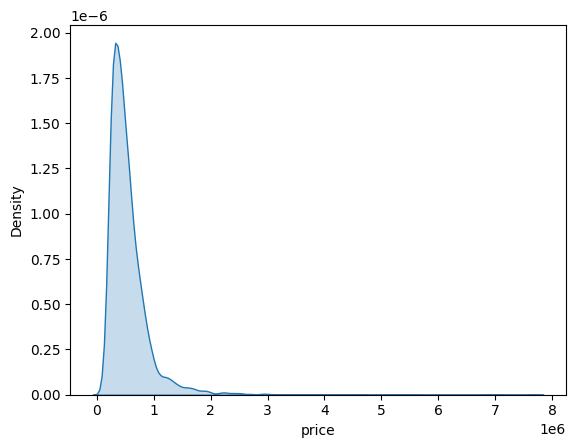

In [ ]:
sns.kdeplot(house_data['price'], fill = True)

In [ ]:
house_data['price'].skew()

np.float64(4.024069144684712)

Is there any outliers ?

<Axes: xlabel='price'>

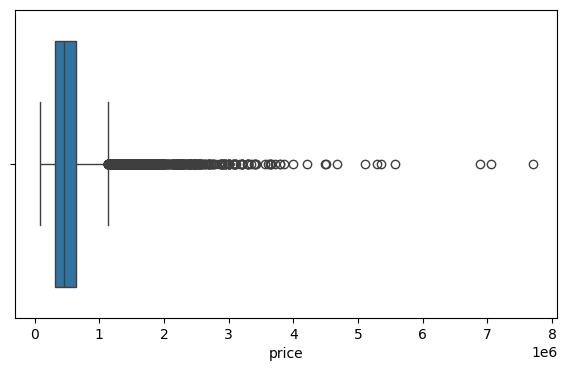

In [ ]:
plt.figure(figsize=(7,4))
sns.boxplot(house_data['price'], orient = 'h')

5. Handling Outliers

In [ ]:
def outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = (data[column] < lower_bound) | (data[column] > upper_bound)
    return data.index[outliers]

In [ ]:
outliers_iqr(house_data, 'price')    # rows indexes having outliers

Index([    5,    21,    49,    69,   125,   153,   216,   246,   269,   270,
       ...
       21525, 21530, 21532, 21540, 21551, 21568, 21576, 21590, 21597, 21600],
      dtype='int64', length=1146)

In [ ]:
from scipy import LowLevelCallable
Q1 = house_data['price'].quantile(0.25)
Q3 = house_data['price'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [ ]:
house_data['price'] = house_data['price'].clip(lower = lower_bound, upper=upper_bound)

<Axes: xlabel='price'>

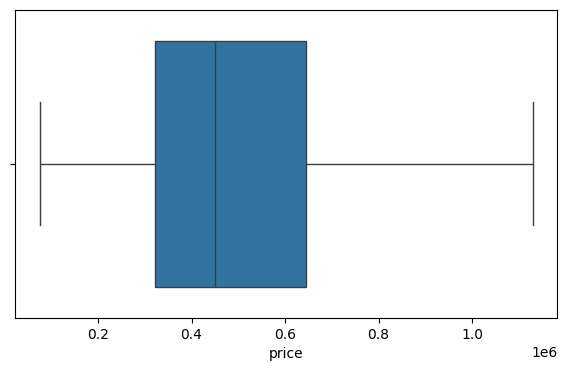

In [ ]:
plt.figure(figsize=(7,4))
sns.boxplot(house_data['price'], orient = 'h')

<Axes: xlabel='price', ylabel='Density'>

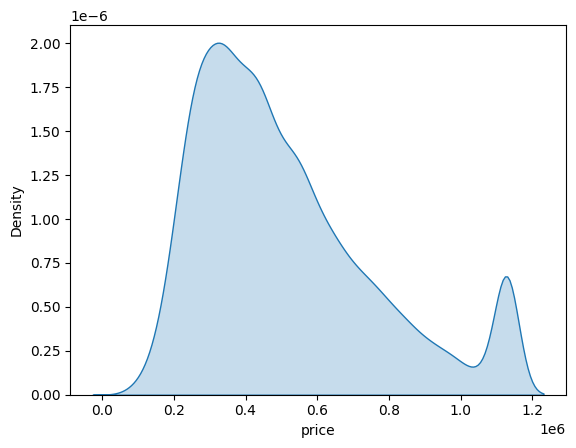

In [ ]:
sns.kdeplot(house_data['price'], fill = True)

4. Is there any Multicollinearity ?

* VIF - Variance Inflation Factor this is a metric to measure multicollinearity in regression model.
* Regress Xi on all other features and measure how well this explains all other features.

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
x = house_data.drop(['id', 'date', 'price'], axis = 1)

In [ ]:
vif_data = pd.DataFrame()
vif_data["feature"] = x.columns
vif_data["VIF"] = [variance_inflation_factor(x.values, i) for i in range(len(x.columns))]
vif_data

/usr/local/lib/python3.12/dist-packages/statsmodels/stats/outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,feature,VIF
0,bedrooms,2.327239e+01
1,bathrooms,2.861188e+01
2,sqft_living,inf
3,sqft_lot,2.377656e+00
4,floors,1.689222e+01
5,waterfront,1.212827e+00
6,view,1.551834e+00
7,condition,3.471167e+01
8,grade,1.473809e+02
9,sqft_above,inf


5. Features & Target

In [ ]:
X = house_data.drop(['id', 'date', 'sqft_above', 'sqft_basement', 'zipcode', 'yr_renovated', 'long', 'price'], axis = 1)
Y = house_data['price']

6. Split Train & Test

In [ ]:
# random sample of data from X & Y
# test_size = 20% , train_size = 80%, random_state = 2 (seed)
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size = 0.2, random_state=2)

7. Data Preprocessing

In [ ]:
# In Regression - Standardization of features are important stage
from sklearn.preprocessing import StandardScaler
# It
scaler = StandardScaler()
x_train_scaler = scaler.fit_transform(x_train)
x_test_scaler = scaler.transform(x_test)

8. Linear Regression

In [ ]:
lin_reg = LinearRegression()
# fit() - train the model with samples data
lin_reg.fit(x_train_scaler, y_train)

LinearRegression()

In [ ]:
lin_reg.score(x_test_scaler, y_test)

0.7525720681049568

9. Linear Regression Metrics

In [ ]:
# R2 (coefficient of determination) - This tells you how much target variability is explained by model.
# R2 range (0-1)
Y_pred = lin_reg.predict(x_test_scaler)
r2_score(y_test, Y_pred)

0.7525720681049568

10. Regression Metrics

In [ ]:
Y_pred = lin_reg.predict(x_test_scaler)
print("Mean Squared Error: ", mean_squared_error(y_test, Y_pred))
print("Mean Absolute Error: ", mean_absolute_error(y_test, Y_pred))
print("Root Mean Squared Error: ", np.sqrt(mean_squared_error(y_test, Y_pred)))
print("Mean Absolute Percentage Error: ", mean_absolute_percentage_error(y_test, Y_pred))

Mean Squared Error:  15661366172.316086
Mean Absolute Error:  92789.8079003426
Root Mean Squared Error:  125145.38014771494
Mean Absolute Percentage Error:  0.20375387091625252


11. Regression Plot

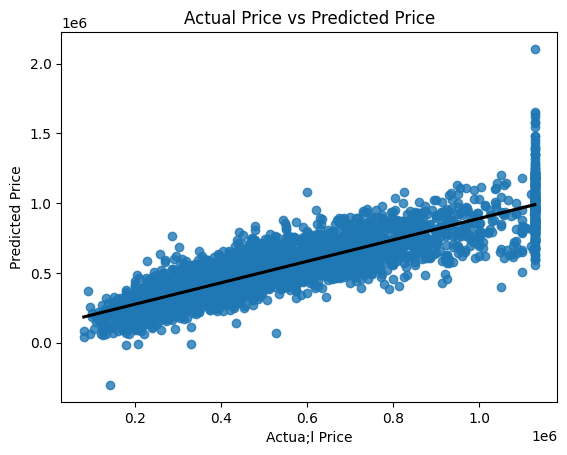

In [ ]:
sns.regplot(x = y_test, y = Y_pred, line_kws={'color':'black'})
plt.xlabel('Actua;l Price')
plt.ylabel('Predicted Price')
plt.title('Actual Price vs Predicted Price')
plt.show()

11. New Sample

In [ ]:
x_new_sample = x_test.sample(1)

In [ ]:
x_new_sample

,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,yr_built,lat,sqft_living15,sqft_lot15
16688,4,2.5,2460,7350,2.0,0,0,3,9,1989,47.3061,2390,8568


In [ ]:
x_scaled = scaler.transform(x_new_sample)

In [ ]:
lin_reg.predict(x_scaled)

array([498589.5345599])

12. Coeff. & Intercept

In [ ]:
lin_reg.coef_

array([ -5883.47283304,  22982.51330732,  59483.19327545,   7562.0074894 ,
        17257.19573142,   8907.82547832,  23895.41445566,  17889.94146941,
        96218.59237606, -58579.83806289,  75386.40042407,  37707.00634877,
        -4549.72881588])

In [ ]:
lin_reg.intercept_

np.float64(511382.6611336039)